# Figure 4
Row 1: pupil GLM conceptual schematic. Row 2: pupil dilation estimated marginal means by transition (start-aligned), with a per-timebin significance strip for 4 pairwise contrasts. Row 3: pupil-betas transition model estimated marginal means, same comparisons/order/format as the RT row in `figure2.ipynb`.

**Note:** Row 2 needs `analysis_pupiltimeseries/1_timeseries_model.R` re-run (its contrast set was just expanded to all 6 pairwise comparisons) before this notebook will execute end-to-end.

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_pupiltimeseries_emmeans,
    load_pupiltimeseries_contrasts,
    load_pupilbetas_transition_emmeans,
    load_pupilbetas_transition_contrasts,
    DATASET_LABELS,
)
from riskhistory.setup_pupilbetas.utils_prf import get_prf
from riskhistory.setup_pupilbetas.utils_create_regressors import (
    create_timings_matrix,
    convolve_with_prf,
)
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions
Shared transition color/short-code mapping (AA=accept_to_accept, AR=accept_to_reject, RA=reject_to_accept, RR=reject_to_reject) and the 4 pairwise contrasts, reused by both Row 1 and Row 3. Same color scheme as the RT plot in `figure2.ipynb`.

In [ ]:
# AA/AR/RA/RR = (previous choice, current choice): AA=accept_to_accept,
# AR=accept_to_reject, RA=reject_to_accept, RR=reject_to_reject
TRANSITION_SHORT = {
    "accept_to_accept": "AA",
    "accept_to_reject": "AR",
    "reject_to_accept": "RA",
    "reject_to_reject": "RR",
}
TRANSITION_COLORS = {
    "accept_to_accept": "#E5383B", #"#D62728",
    "accept_to_reject": "#86102C", #"#F4A6A6",
    "reject_to_accept": "#228A9F", #"#A6C1E8",
    "reject_to_reject": "#1A237E", #"#1F4E9C",
}
# x-axis order: AA, AR, RR, RA
BAR_ORDER = ["accept_to_accept", "accept_to_reject", "reject_to_reject", "reject_to_accept"]
# Same 4 pairwise comparisons as figure2.ipynb's RT row
BRACKET_PAIRS = [
    ("accept_to_accept", "accept_to_reject"),  # AA vs AR: within Prev. Accept
    ("reject_to_reject", "reject_to_accept"),  # RR vs RA: within Prev. Reject
]


def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y - h, sig_stars(p), ha="center", va="bottom")


def lookup_contrast(contrasts_df, label_a, label_b):
    """Contrast labels are 'A - B'; try both orderings."""
    for cand in (f"{label_a} - {label_b}", f"{label_b} - {label_a}"):
        match = contrasts_df[contrasts_df["contrast"] == cand]
        if len(match):
            return match.iloc[0]
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")


def get_contrast_timeseries(contrasts_df, dataset, label_a, label_b):
    """Same as lookup_contrast, but returns the full per-timebin series
    (sorted by timebin) instead of a single row."""
    ds_df = contrasts_df[contrasts_df["dataset"] == dataset]
    for cand in (f"{label_a} - {label_b}", f"{label_b} - {label_a}"):
        sub = ds_df[ds_df["contrast"] == cand]
        if len(sub):
            return sub.sort_values("timebin")
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")

### Build pupil GLM schematic data
Same construction as `pupilglm_schematic.ipynb`: 4 regressors built with the real `create_timings_matrix`, convolved with the real PRF, summed with different weights + smoothed noise into a simulated "real" pupil signal.

In [3]:
FS = 25          # samples/sec, matches the real pipeline's default
T_MAX = 8.0      # seconds shown for the regressor rows and real pupil signal
PRF_MAX_SECS = 4.0

time_vector = np.arange(0, T_MAX, 1 / FS)

onset_matrix, _ = create_timings_matrix(
    trial_timings={1: 0.5, 2: 5.0}, time_vector=time_vector, trial_durations=None,
    option="all", sub=None, run=None, dataset=None, regressor_name="onset",
)
button_matrix, _ = create_timings_matrix(
    trial_timings={1: 2.0, 2: 6.0}, time_vector=time_vector, trial_durations=None,
    option="all", sub=None, run=None, dataset=None, regressor_name="button",
)
decision_matrix, _ = create_timings_matrix(
    trial_timings={1: 0.5, 2: 5.0}, time_vector=time_vector,
    trial_durations={1: 1.5, 2: 1.0}, option="ls-a",
    sub=None, run=None, dataset=None, regressor_name="decision",
)

SCHEMATIC_REGRESSORS = {
    "Stimuli\nOnset":    onset_matrix[:, 0],
    "Button\nPresses":   button_matrix[:, 0],
    "Decision\nTrial 1": decision_matrix[:, 0],
    "Decision\nTrial 2": decision_matrix[:, 1],
}

prf = get_prf(max_secs=PRF_MAX_SECS, width=10.1, time_to_peak=930, sampling_rate=FS)
prf_time = np.arange(0, PRF_MAX_SECS, 1 / FS)[: len(prf)]

schematic_convolved = {
    name: convolve_with_prf(reg.reshape(-1, 1), prf, normalize=True)[:, 0]
    for name, reg in SCHEMATIC_REGRESSORS.items()
}

SCHEMATIC_BETAS = {
    "Stimuli\nOnset": 0.3,
    "Button\nPresses": 0.25,
    "Decision\nTrial 1": 1.0,
    "Decision\nTrial 2": 0.8,
}
schematic_predicted = sum(
    SCHEMATIC_BETAS[name] * schematic_convolved[name] for name in SCHEMATIC_REGRESSORS
)

_rng = np.random.default_rng(0)
_raw_noise = _rng.normal(0, 1, size=len(time_vector))
_smooth_noise = np.convolve(_raw_noise, np.ones(5) / 5, mode="same") * 0.06
schematic_real_signal = schematic_predicted


### Figure 4: 3 rows x 3 columns
Columns = datasets (title only on row 1). Outer figure split into 3 vertically-stacked subfigures so row 2's schematic (not dataset-specific) can span the full width as one nested grid.

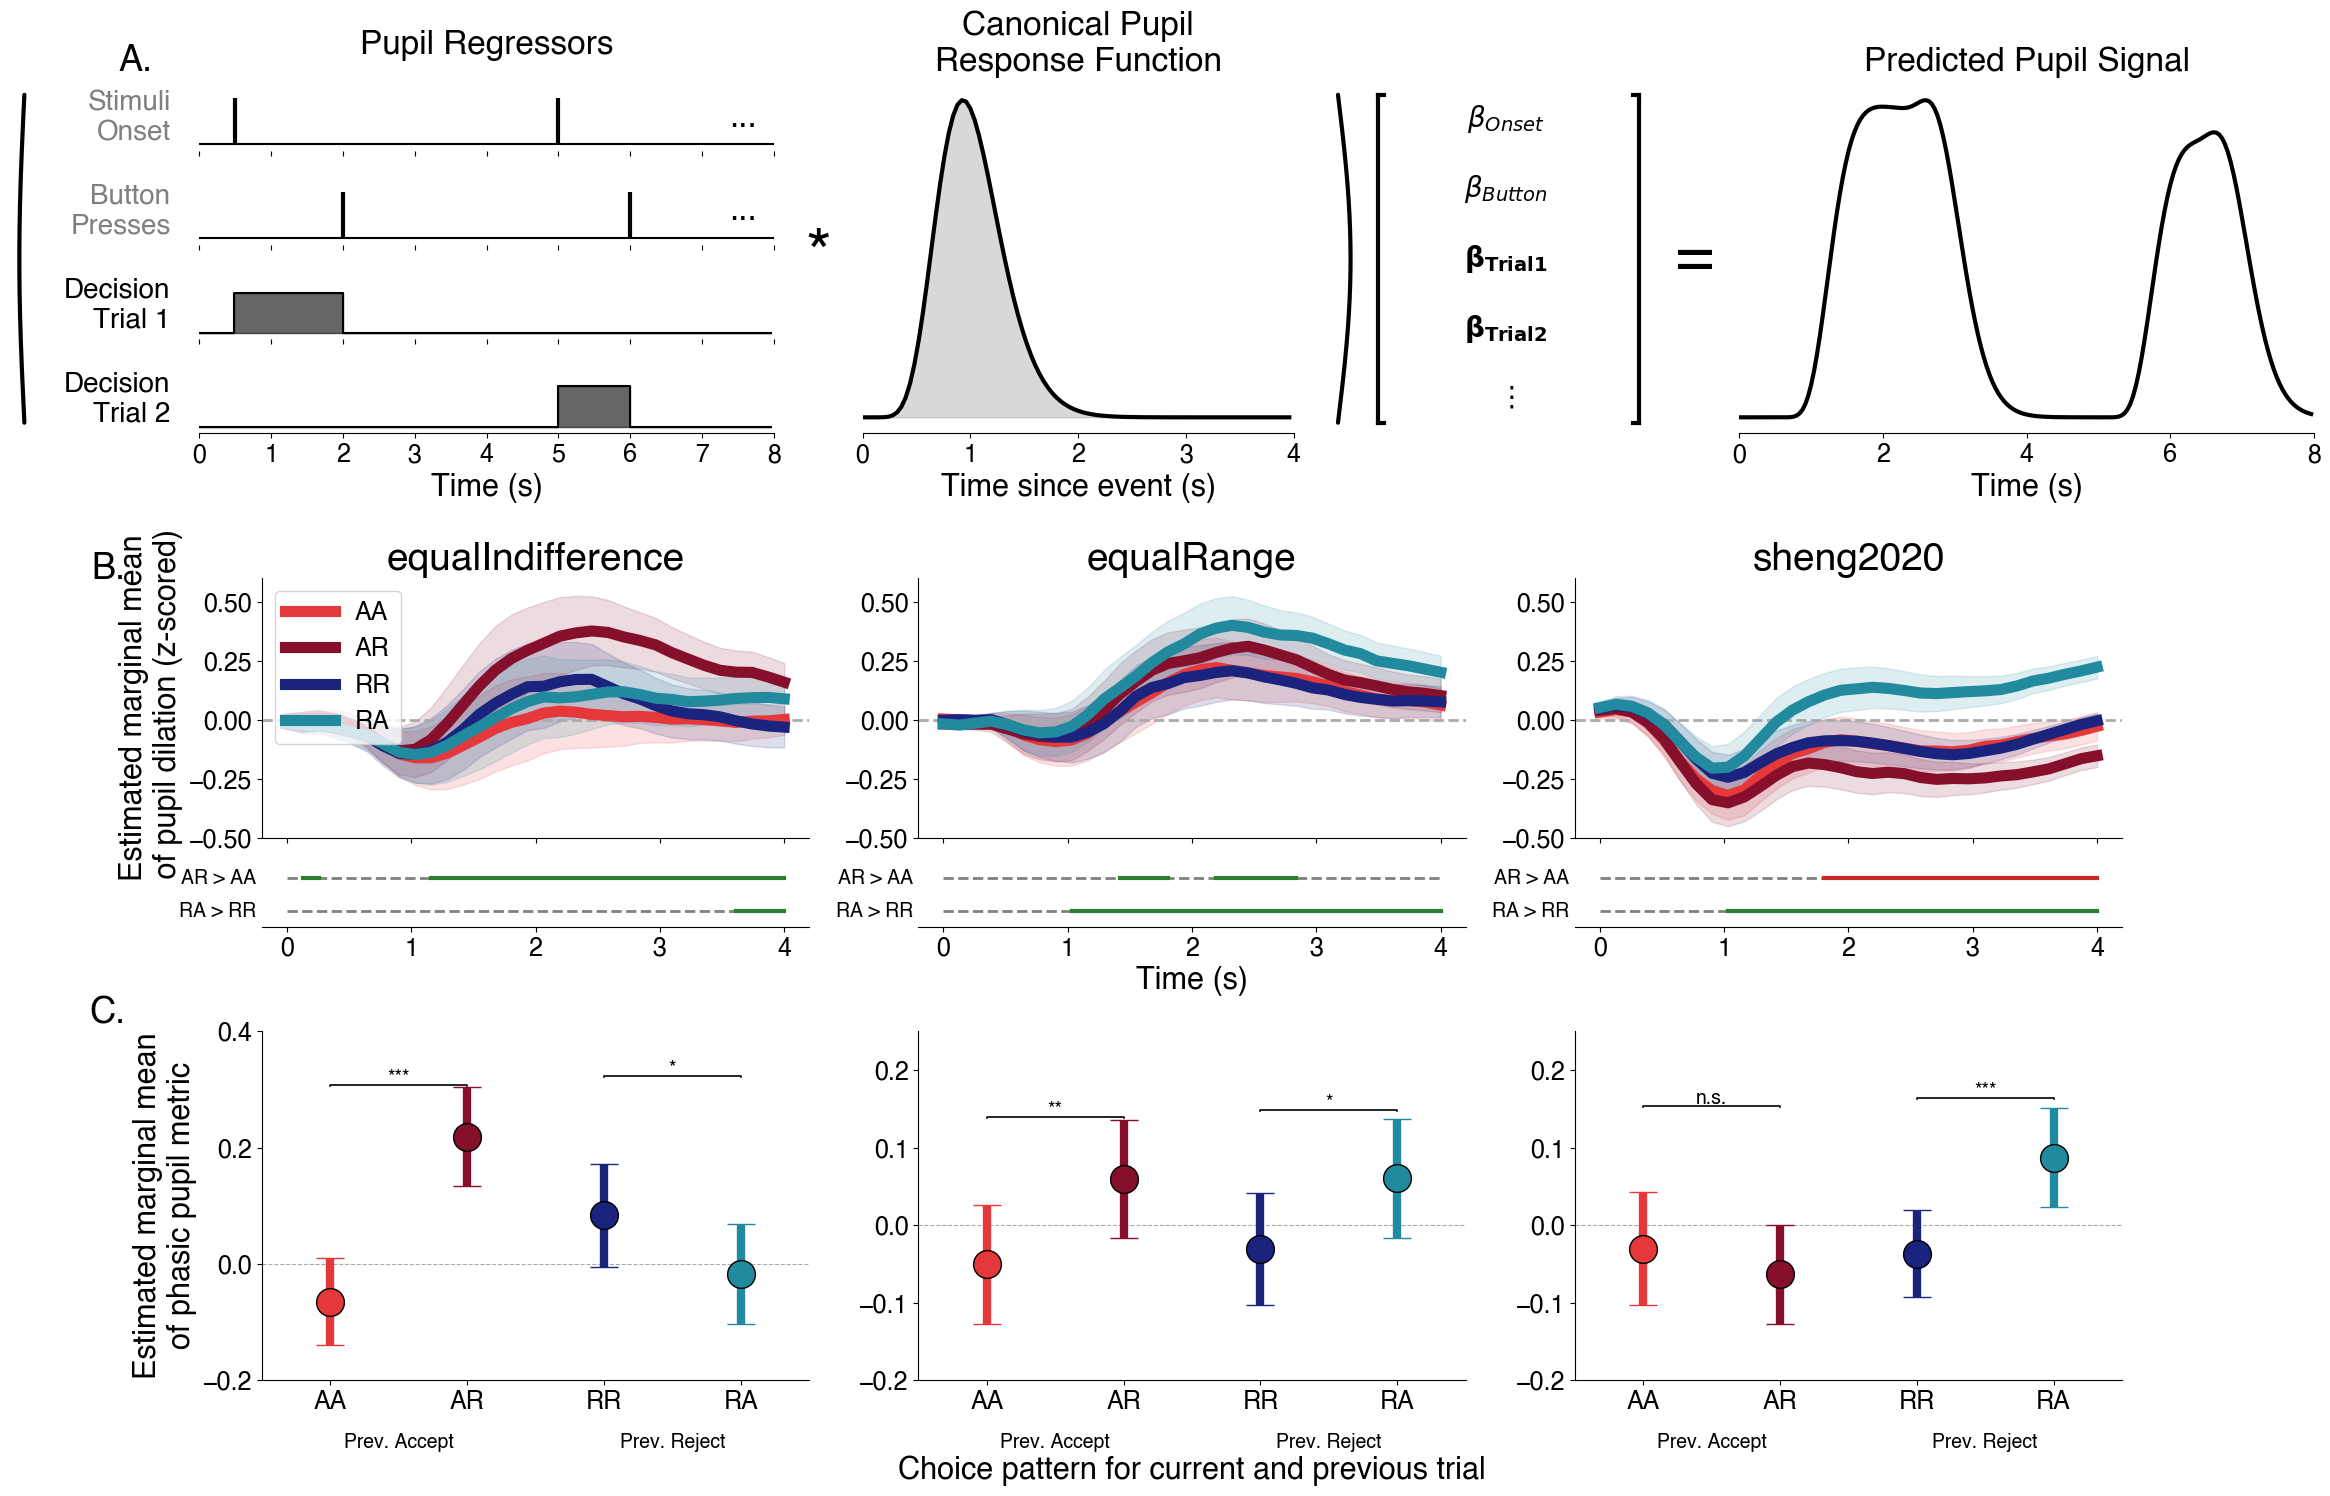

In [84]:
fig = plt.figure(figsize=(24, 14))
outer_subfigs = fig.subfigures(nrows=2, ncols=1, height_ratios=[1.5, 3], hspace=0.06)
bottom_subfigs = outer_subfigs[1].subfigures(nrows=2, ncols=1, height_ratios=[1.5, 1.5])
subfigs = [outer_subfigs[0], bottom_subfigs[0], bottom_subfigs[1]]

# =============================================================================
# Row 1: Pupil GLM conceptual schematic
# =============================================================================
SCHEM_ROW_NAMES = ["Stimuli\nOnset", "Button\nPresses", "Decision\nTrial 1", "Decision\nTrial 2"]
SCHEM_ROW_COLORS = {
    "Stimuli\nOnset": "#000000",
    "Button\nPresses": "#000000",
    "Decision\nTrial 1": "#000000",
    "Decision\nTrial 2": "#000000",
}

def _draw_big_paren(ax, direction=1, lw=3, color="black", curvature=0.35,
                    y_bottom=0.03, y_top=0.97, x_center=0.5):
    """direction=+1 draws '(' (bulges right), -1 draws ')' (bulges left)."""
    y = np.linspace(y_bottom, y_top, 200)
    x = x_center + direction * curvature * np.sin(np.pi * (y - y_bottom) / (y_top - y_bottom))
    ax.plot(x, y, color=color, lw=lw, solid_capstyle="round", clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

def _draw_big_bracket(ax, direction=1, lw=3, color="black", tick=0.2,
                      y_bottom=0.03, y_top=0.97, x=0.6):
    """direction=+1 draws '[' (ticks point right), -1 draws ']' (ticks point left)."""
    ax.plot([x, x], [y_bottom, y_top], color=color, lw=lw, clip_on=False)
    ax.plot([x, x + direction * tick], [y_top, y_top], color=color, lw=lw, clip_on=False)
    ax.plot([x, x + direction * tick], [y_bottom, y_bottom], color=color, lw=lw, clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

gs1 = subfigs[0].add_gridspec(
    nrows=4, ncols=11,
    width_ratios=[0.1, 1.0, 4, 0.4, 3, 0.25, 0.2, 1.4, 0.2, 0.4, 4],
    wspace=0.08, hspace=0.4, left=0.02, right=0.98,
)

schem_paren_left_ax = subfigs[0].add_subplot(gs1[:, 0])
schem_paren_left_spacer_ax = subfigs[0].add_subplot(gs1[:, 1]); schem_paren_left_spacer_ax.axis("off")
schem_row_axes = [subfigs[0].add_subplot(gs1[i, 2]) for i in range(4)]
for i in range(1, 4):
    schem_row_axes[i].sharex(schem_row_axes[0])

schem_symbol1_ax = subfigs[0].add_subplot(gs1[:, 3]); schem_symbol1_ax.axis("off")
schem_prf_ax = subfigs[0].add_subplot(gs1[:, 4])
schem_paren_right_ax = subfigs[0].add_subplot(gs1[:, 5])
schem_bracket_left_ax = subfigs[0].add_subplot(gs1[:, 6])
schem_beta_vec_ax = subfigs[0].add_subplot(gs1[:, 7])
schem_bracket_right_ax = subfigs[0].add_subplot(gs1[:, 8])
schem_symbol2_ax = subfigs[0].add_subplot(gs1[:, 9]); schem_symbol2_ax.axis("off")
schem_signal_ax = subfigs[0].add_subplot(gs1[:, 10])

for i, name in enumerate(SCHEM_ROW_NAMES):
    ax = schem_row_axes[i]
    reg = SCHEMATIC_REGRESSORS[name]
    color = SCHEM_ROW_COLORS[name]

    if name in ("Stimuli\nOnset", "Button\nPresses"):
        event_times = [0.5, 5.0] if name == "Stimuli\nOnset" else [2.0, 6.0]
        ax.axhline(0, color=color, linewidth=1.5, zorder=1)
        ax.vlines(event_times, ymin=0, ymax=1, color=color, linewidth=3, zorder=2)
        ax.set_ylim(-0.15, 1.3)
        ax.text(0.97, 0.5, "...", transform=ax.transAxes, ha="right", va="center",
               fontsize=24, fontweight="bold")
    else:
        ax.fill_between(time_vector, reg, step="post", color=color, alpha=0.6)
        ax.plot(time_vector, reg, drawstyle="steps-post", color=color, linewidth=1.5)
        ax.set_ylim(-0.15 * reg.max(), reg.max() * 1.5)

    ax.set_xlim(0, T_MAX)
    ax.set_xticks(np.arange(0, T_MAX + 1, 1))
    ax.set_yticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    if "Decision" in name:
        ax.text(-0.05, 0.5, name, transform=ax.transAxes, ha="right", va="center",
               fontsize=20, color="black")
    else:
        ax.text(-0.05, 0.5, name, transform=ax.transAxes, ha="right", va="center",
               fontsize=20, color="grey")

    if i < 3:
        ax.tick_params(labelbottom=False)
        ax.spines["bottom"].set_visible(False)
    else:
        ax.set_xlabel("Time (s)")

trial2_reg = SCHEMATIC_REGRESSORS["Decision\nTrial 2"]

schem_row_axes[0].text(0.5, 1.35, "Pupil Regressors", transform=schem_row_axes[0].transAxes,
                       ha="center", va="bottom", fontweight="bold", fontsize=24)

schem_symbol1_ax.text(0.5, 0.5, "*", ha="center", va="center", fontsize=48,
                     transform=schem_symbol1_ax.transAxes)

schem_prf_ax.plot(prf_time, prf, color="black", linewidth=3)
schem_prf_ax.fill_between(prf_time, prf, color="gray", alpha=0.3)
schem_prf_ax.set_xlim(0, PRF_MAX_SECS)
schem_prf_ax.set_xlabel("Time since event (s)")
schem_prf_ax.set_yticks([])
schem_prf_ax.spines["top"].set_visible(False)
schem_prf_ax.spines["right"].set_visible(False)
schem_prf_ax.spines["left"].set_visible(False)
schem_prf_ax.text(0.5, 1.02, "Canonical Pupil\nResponse Function",
                  transform=schem_prf_ax.transAxes, ha="center", va="bottom",
                  fontstyle="italic", fontsize=24)

# Big "( ... )" spanning from the left of the regressor stack to the right
# of the PRF panel -- groups "regressors * PRF" as a single term (the
# convolved design matrix).
_draw_big_paren(schem_paren_left_ax, direction=-1, x_center=1)
_draw_big_paren(schem_paren_right_ax, direction=1, x_center=0.8)

# Beta column vector, wrapped in a big "[ ... ]", multiplying the
# parenthesized convolved-design term.
BETA_VEC_LABELS = [r"$\beta_{Onset}$", r"$\beta_{Button}$",
                  r"$\mathbf{\beta_{Trial1}}$", r"$\mathbf{\beta_{Trial2}}$", r"$\vdots$"]
_draw_big_bracket(schem_bracket_left_ax, direction=1)
_draw_big_bracket(schem_bracket_right_ax, direction=-1)
schem_beta_vec_ax.set_xlim(0, 1)
schem_beta_vec_ax.set_ylim(0, 1)
schem_beta_vec_ax.axis("off")
n_beta = len(BETA_VEC_LABELS)
for i, lbl in enumerate(BETA_VEC_LABELS):
    y = 1 - (i + 0.5) / n_beta
    schem_beta_vec_ax.text(0.5, y, lbl, ha="center", va="center", fontsize=20)

schem_symbol2_ax.text(0.5, 0.5, "=", ha="center", va="center", fontsize=48,
                     transform=schem_symbol2_ax.transAxes)

schem_signal_ax.plot(time_vector, schematic_real_signal, color="black", linewidth=3)
schem_signal_ax.set_xlim(0, T_MAX)
schem_signal_ax.set_xlabel("Time (s)")
schem_signal_ax.set_yticks([])
schem_signal_ax.spines["top"].set_visible(False)
schem_signal_ax.spines["right"].set_visible(False)
schem_signal_ax.spines["left"].set_visible(False)
schem_signal_ax.text(0.5, 1.02, "Predicted Pupil Signal", transform=schem_signal_ax.transAxes,
                    ha="center", va="bottom", fontweight="bold", fontsize=24)

# =============================================================================
# Row 2: Pupil dilation by transition (start-aligned)
# =============================================================================
emmeans_start = load_pupiltimeseries_emmeans(alignment="start")
contrasts_start = load_pupiltimeseries_contrasts(alignment="start")

SIG_COLOR_TRUE = "#2E7D32"   # directional claim holds (and is significant)
SIG_COLOR_FALSE = "#C62828"  # directional claim does not hold

# (higher_label, lower_label): tests "higher > lower" at each timepoint.
DIRECTIONAL_CONTRASTS = [
    ("accept_to_reject", "accept_to_accept"),  # AR > AA
    ("reject_to_accept", "reject_to_reject"),  # RA > RR
]

def get_directional_estimate(contrasts_df, dataset, higher_label, lower_label):
    """Same lookup as get_contrast_timeseries, but sign-normalized so a
    positive estimate always means higher_label > lower_label."""
    ts = get_contrast_timeseries(contrasts_df, dataset, higher_label, lower_label)
    estimate = ts["estimate"].values
    if ts["contrast"].iloc[0] == f"{lower_label} - {higher_label}":
        estimate = -estimate
    return ts["timebin"].values, ts["p.value"].values, estimate

axes0 = subfigs[1].subplots(nrows=2, ncols=3, sharex="col",
                            gridspec_kw={"height_ratios": [4, 1], "hspace": 0.15})

for col, ds in enumerate(DATASETS):
    main_ax = axes0[0, col]
    sig_ax = axes0[1, col]
    ds_emm = emmeans_start[emmeans_start["dataset"] == ds]

    for level in BAR_ORDER:
        level_emm = ds_emm[ds_emm["transition"] == level].sort_values("timebin")
        color = TRANSITION_COLORS[level]
        main_ax.plot(level_emm["timebin"], level_emm["emmean"], color=color,
                    linewidth=8, label=TRANSITION_SHORT[level] if col == 0 else None)
        main_ax.fill_between(level_emm["timebin"], level_emm["asymp.LCL"],
                             level_emm["asymp.UCL"], color=color, alpha=0.15)

    main_ax.axhline(0, color="#aaaaaa", linewidth=2, linestyle="--", zorder=1)
    main_ax.set_ylim(-0.5, 0.6)
    main_ax.set_title(DATASET_LABELS.get(ds, ds))
    main_ax.tick_params(labelbottom=False)
    main_ax.spines["top"].set_visible(False)
    main_ax.spines["right"].set_visible(False)
    if col == 0:
        main_ax.set_ylabel("Estimated marginal mean\n of pupil dilation (z-scored)")
        main_ax.legend(loc="upper left", frameon=True)

    n_contrasts = len(DIRECTIONAL_CONTRASTS)
    for row_idx, (higher_label, lower_label) in enumerate(DIRECTIONAL_CONTRASTS):
        y_level = n_contrasts - 1 - row_idx
        timebins, pvals, estimate = get_directional_estimate(
            contrasts_start, ds, higher_label, lower_label
        )

        sig = pvals < 0.05
        higher_greater = np.where(sig & (estimate > 0), y_level, np.nan)
        higher_lesser = np.where(sig & (estimate < 0), y_level, np.nan)

        sig_ax.plot(timebins, np.full_like(timebins, y_level, dtype=float),
                   linestyle="--", color="gray", linewidth=2)
        sig_ax.plot(timebins, higher_greater, linestyle="-", color=SIG_COLOR_TRUE, linewidth=3)
        sig_ax.plot(timebins, higher_lesser, linestyle="-", color=SIG_COLOR_FALSE, linewidth=3)

        contrast_label = f"{TRANSITION_SHORT[higher_label]} > {TRANSITION_SHORT[lower_label]}"
        sig_ax.text(-0.01, y_level, contrast_label, transform=sig_ax.get_yaxis_transform(),
                   ha="right", va="center", fontsize=14)

    sig_ax.set_ylim(-0.5, n_contrasts - 0.5)
    sig_ax.set_yticks([])
    sig_ax.spines["top"].set_visible(False)
    sig_ax.spines["right"].set_visible(False)
    sig_ax.spines["left"].set_visible(False)
    if col == 1:
        sig_ax.set_xlabel("Time (s)")

# =============================================================================
# Row 3: Pupil-betas transition model estimated marginal means
# =============================================================================
pupilbetas_emm = load_pupilbetas_transition_emmeans()
pupilbetas_contrasts = load_pupilbetas_transition_contrasts()

axes2 = subfigs[2].subplots(nrows=1, ncols=3)

for col, ds in enumerate(DATASETS):
    ax = axes2[col]
    ds_emm = pupilbetas_emm[pupilbetas_emm["dataset"] == ds]
    ds_contrasts = pupilbetas_contrasts[pupilbetas_contrasts["dataset"] == ds]

    x_pos = np.arange(len(BAR_ORDER))
    means, los, his = [], [], []
    for level in BAR_ORDER:
        row = ds_emm[ds_emm["transition"] == level].iloc[0]
        means.append(row["emmean"])
        los.append(row["asymp.LCL"])
        his.append(row["asymp.UCL"])
    means, los, his = np.array(means), np.array(los), np.array(his)
    yerr = [means - los, his - means]
    colors = [TRANSITION_COLORS[level] for level in BAR_ORDER]

    for i in range(len(BAR_ORDER)):
        ax.errorbar(x_pos[i], means[i], yerr=[[yerr[0][i]], [yerr[1][i]]],
                   fmt="o", color=colors[i], markersize=20,
                   markeredgecolor="black", markeredgewidth=1,
                   ecolor=colors[i], elinewidth=6, capsize=10, zorder=2)

    y_top, y_bottom = his.max(), los.min()
    y_range = y_top - y_bottom
    bracket_h = 0.005 * y_range
    for tier, (label_a, label_b) in enumerate(BRACKET_PAIRS):
        row = lookup_contrast(ds_contrasts, label_a, label_b)
        p_val = row["p_adj_bh"]
        x1, x2 = sorted([BAR_ORDER.index(label_a), BAR_ORDER.index(label_b)])
        y_bracket = y_top + (0.005 + 0.035 * tier) * y_range
        add_significance_bracket(ax, x1, x2, y_bracket, bracket_h, p_val)

    ylim_top = y_top + (0.15 + 0.2 * (len(BRACKET_PAIRS) - 1)) * y_range + 2 * bracket_h
    ax.set_ylim(y_bottom - 0.1 * y_range, ylim_top)

    ax.set_xticks(x_pos)
    if col == 0:
        ax.set_ylim(-0.2, 0.4)
    elif col == 1:
        ax.set_ylim(-0.2, 0.25)
    elif col == 2:
        ax.set_ylim(-0.2, 0.25)
    ax.set_xlim(x_pos[0] - 0.5, x_pos[-1] + 0.5)
    ax.set_xticklabels([TRANSITION_SHORT[level] for level in BAR_ORDER])
    ax.axhline(0, color="#aaaaaa", linewidth=0.8, linestyle="--", zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.text(0.5, -0.15, "Prev. Accept", transform=ax.get_xaxis_transform(),
           ha="center", va="top")
    ax.text(2.5, -0.15, "Prev. Reject", transform=ax.get_xaxis_transform(),
           ha="center", va="top")

    if col == 0:
        ax.set_ylabel("Estimated marginal mean\nof phasic pupil metric")
    if col == 1:
        ax.set_xlabel("Choice pattern for current and previous trial", labelpad=30)

# Row labels, placed just outside the top-left corner of each row's leftmost panel
# (same convention as figure1.ipynb's "A."/"B."/"C.")
subfigs[0].text(0.065, 0.97, "A.", transform=subfigs[0].transSubfigure,
               fontsize=26, fontweight="bold", va="top", ha="left")
axes0[0, 0].text(-0.25, 1.1, "B.", transform=axes0[0, 0].transAxes,
                fontsize=26, fontweight="bold", va="top", ha="right")
axes2[0].text(-0.25, 1.1, "C.", transform=axes2[0].transAxes,
             fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure4.svg", dpi=300, bbox_inches="tight")

plt.show()
